# Benchmark Results

This notebook reproduces the benchmark figures from the paper.
It compares three RL algorithms (**PPO**, **SAC**, **TD3**) and a set of
planning baselines (**FiPla**, **Constant**, **Random**, **Shading**, **MPC** variants)
on the `survival-second-price-exponential` scenario over **1 000 seeds**.

## How to run this notebook

The notebook reads pre-computed per-step CSVs from `benchmark/benchmark_results/`.
To generate them from scratch:

1. Train the RL agents (`benchmark/train_rl.py`) and the MLP valuation head (`benchmark/train_mlp.py`).
2. Run the evaluation script (`benchmark/evaluate.py`) to produce the CSVs.
3. Adapt the paths and names of the csv files in the cells below depending on the saving paths and names you chose. 

See [`BENCHMARK.md`](BENCHMARK.md) for the full protocol, training commands, hyperparameters,
pretrained model layout, and evaluation steps.

Pre-generated figures are available in [`../figures/`](../figures/) and can be viewed without running anything.

In [1]:
import sys, pathlib
# Notebook lives in benchmark/; add repo root so `benchmark.*` imports resolve
repo_root = pathlib.Path().resolve().parent
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

In [2]:
%matplotlib inline
from benchmark.evaluate import score_matrix
from benchmark import plots
import pandas as pd

## Shading α sweep

Grid search over the shading multiplier α (η = 50). Each α is evaluated over 1 000 seeds; we report mean ± std of total episode reward and the per-seed distribution.

In [2]:
shading_df = pd.read_csv(
    "benchmark_results/"
    "survival-second-price-exponential_eta50_shading_alpha_sweep_2026-04-29_23-36-59.csv"
)

# episode reward = last cum_reward value per (alpha, seed)
shading_summary = (
    shading_df.sort_values(["alpha", "seed", "step"])
    .groupby(["alpha", "seed"])["cum_reward"].last()
    .reset_index()
    .rename(columns={"cum_reward": "episode_reward"})
)

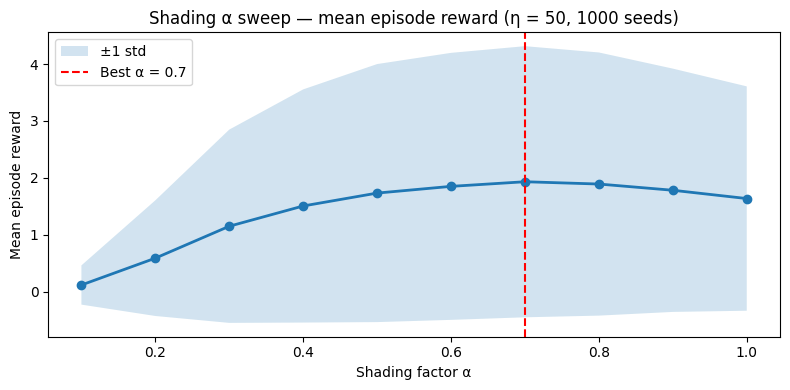

Best α = 0.7  (mean reward = 1.9320)


In [3]:
import matplotlib.pyplot as plt

mean_r = shading_summary.groupby("alpha")["episode_reward"].mean()
std_r  = shading_summary.groupby("alpha")["episode_reward"].std()
best_alpha = mean_r.idxmax()

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(mean_r.index, mean_r.values, marker="o", lw=2)
ax.fill_between(mean_r.index, mean_r - std_r, mean_r + std_r, alpha=0.2, label="±1 std")
ax.axvline(best_alpha, color="red", linestyle="--", label=f"Best α = {best_alpha:.4g}")
ax.set_xlabel("Shading factor α")
ax.set_ylabel("Mean episode reward")
ax.set_title("Shading α sweep — mean episode reward (η = 50, 1000 seeds)")
ax.legend()
plt.tight_layout()
plt.savefig("plots/shading_alpha_sweep_mean.pdf", bbox_inches="tight")
plt.show()
print(f"Best α = {best_alpha:.4g}  (mean reward = {mean_r.max():.4f})")

/tmp/ipykernel_1040923/441405177.py:10: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([f"{a:.2f}" for a in alphas_sorted], rotation=45, ha="right")


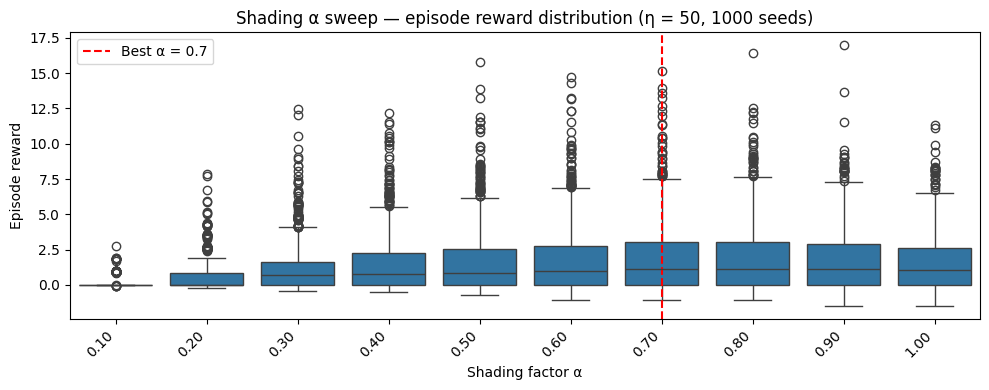

In [4]:
import seaborn as sns

fig, ax = plt.subplots(figsize=(10, 4))
sns.boxplot(
    data=shading_summary, x="alpha", y="episode_reward",
    order=sorted(shading_summary["alpha"].unique()),
    ax=ax,
)
alphas_sorted = sorted(shading_summary["alpha"].unique())
ax.set_xticklabels([f"{a:.2f}" for a in alphas_sorted], rotation=45, ha="right")
ax.axvline(alphas_sorted.index(best_alpha), color="red", linestyle="--", label=f"Best α = {best_alpha:.4g}")
ax.set_xlabel("Shading factor α")
ax.set_ylabel("Episode reward")
ax.set_title("Shading α sweep — episode reward distribution (η = 50, 1000 seeds)")
ax.legend()
plt.tight_layout()
plt.savefig("plots/shading_alpha_sweep_dist.pdf", bbox_inches="tight")
plt.show()

## 1. Load results

Load the saved per-step CSV and build the score matrix (total episode reward per policy per seed) used by rliable.

In [3]:
df_eta50 = pd.read_csv(f"benchmark_results/survival-second-price-exponential_eta50_results_final.csv")

In [4]:
df_eta100 = pd.read_csv(f"benchmark_results/survival-second-price-exponential_eta100_results_final.csv")

In [5]:
scores_eta50 = score_matrix(df_eta50)

In [6]:
scores_eta100 = score_matrix(df_eta100)

Mean number of auction opportunities per episode across all seeds. The horizon is exponentially distributed with rate 1/η, giving a mean campaign length of η auctions.

In [7]:
algos_list = df_eta100["policy"].unique()
algos_list

<StringArray>
[                  'FiPla',            'GreedyMyopic',
               'MPC(H=10)',               'MPC(H=25)',
 'MPCTimeBinned(H=10,K=2)', 'MPCTimeBinned(H=10,K=3)',
 'MPCTimeBinned(H=25,K=2)', 'MPCTimeBinned(H=25,K=3)',
          'Shading(α=0.7)',                     'PPO',
                     'SAC',                     'TD3']
Length: 12, dtype: str

## 2. Plots

### Aggregate metrics

IQM, mean, median, and optimality gap of episode reward across 1000 seeds, with stratified bootstrap confidence intervals (rliable).

  Saved → /home/epatard/Bureau/Inria/paper_ready_code/dynamauction/benchmark/plots/aggregate_metrics_eta50.pdf


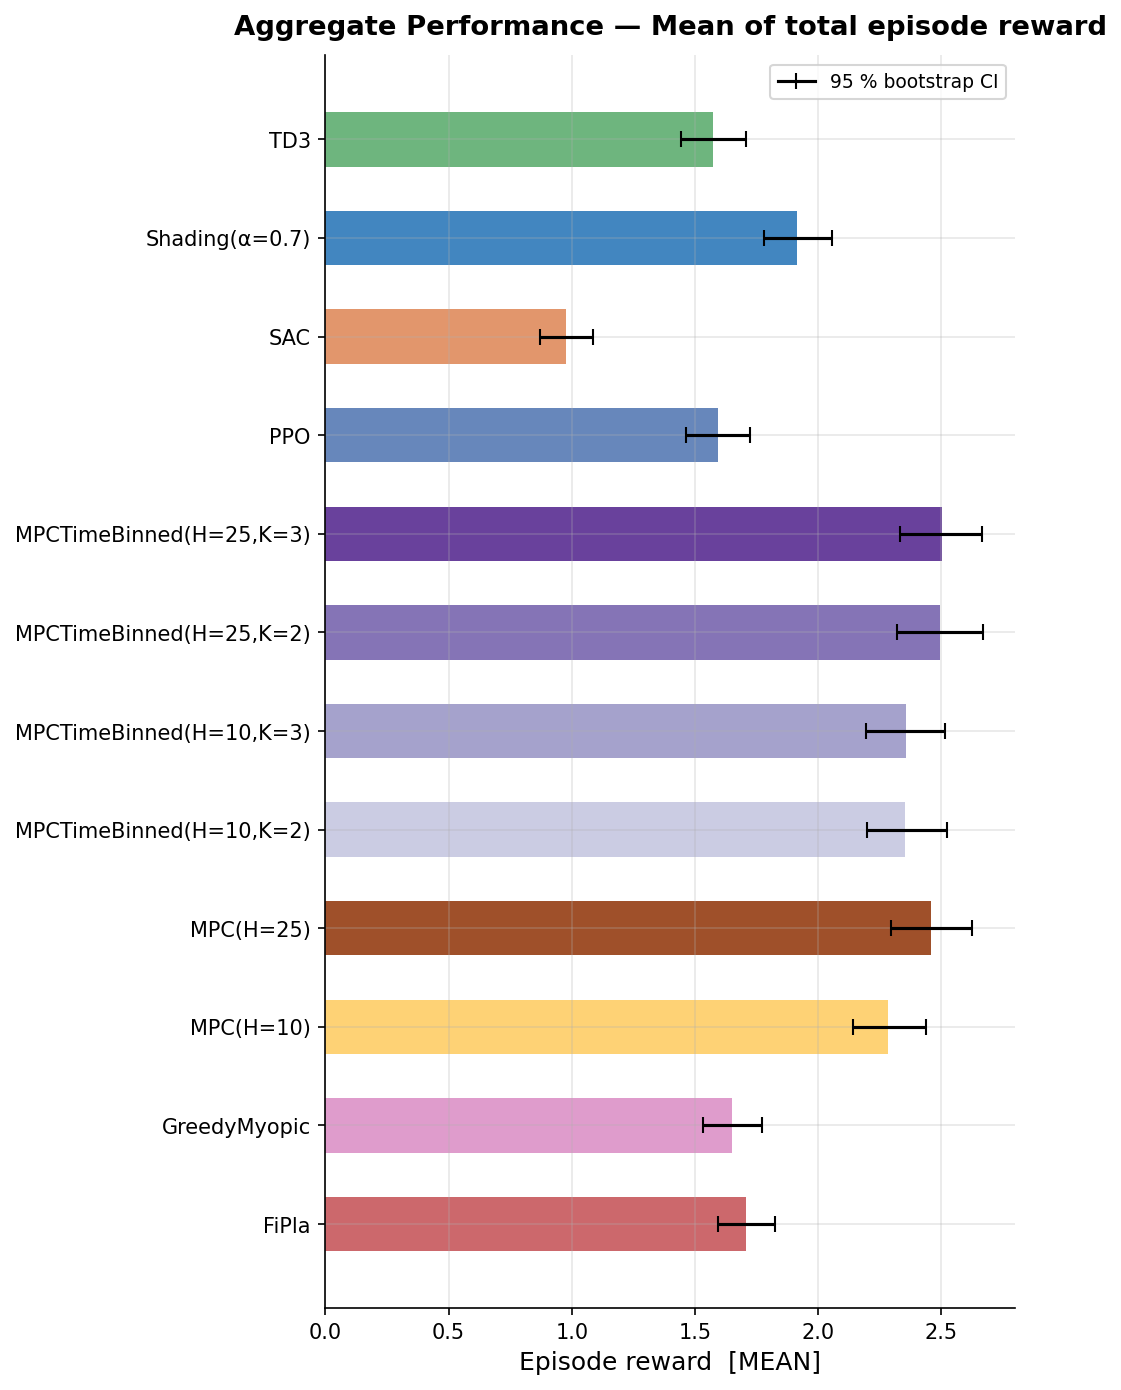

In [7]:
_ = plots.plot_aggregate_metrics(scores_eta50, metric="mean", normalize_by=None, filename="aggregate_metrics_eta50.pdf")

  Saved → /home/epatard/Bureau/Inria/paper_ready_code/dynamauction/benchmark/plots/aggregate_metrics_eta100.pdf


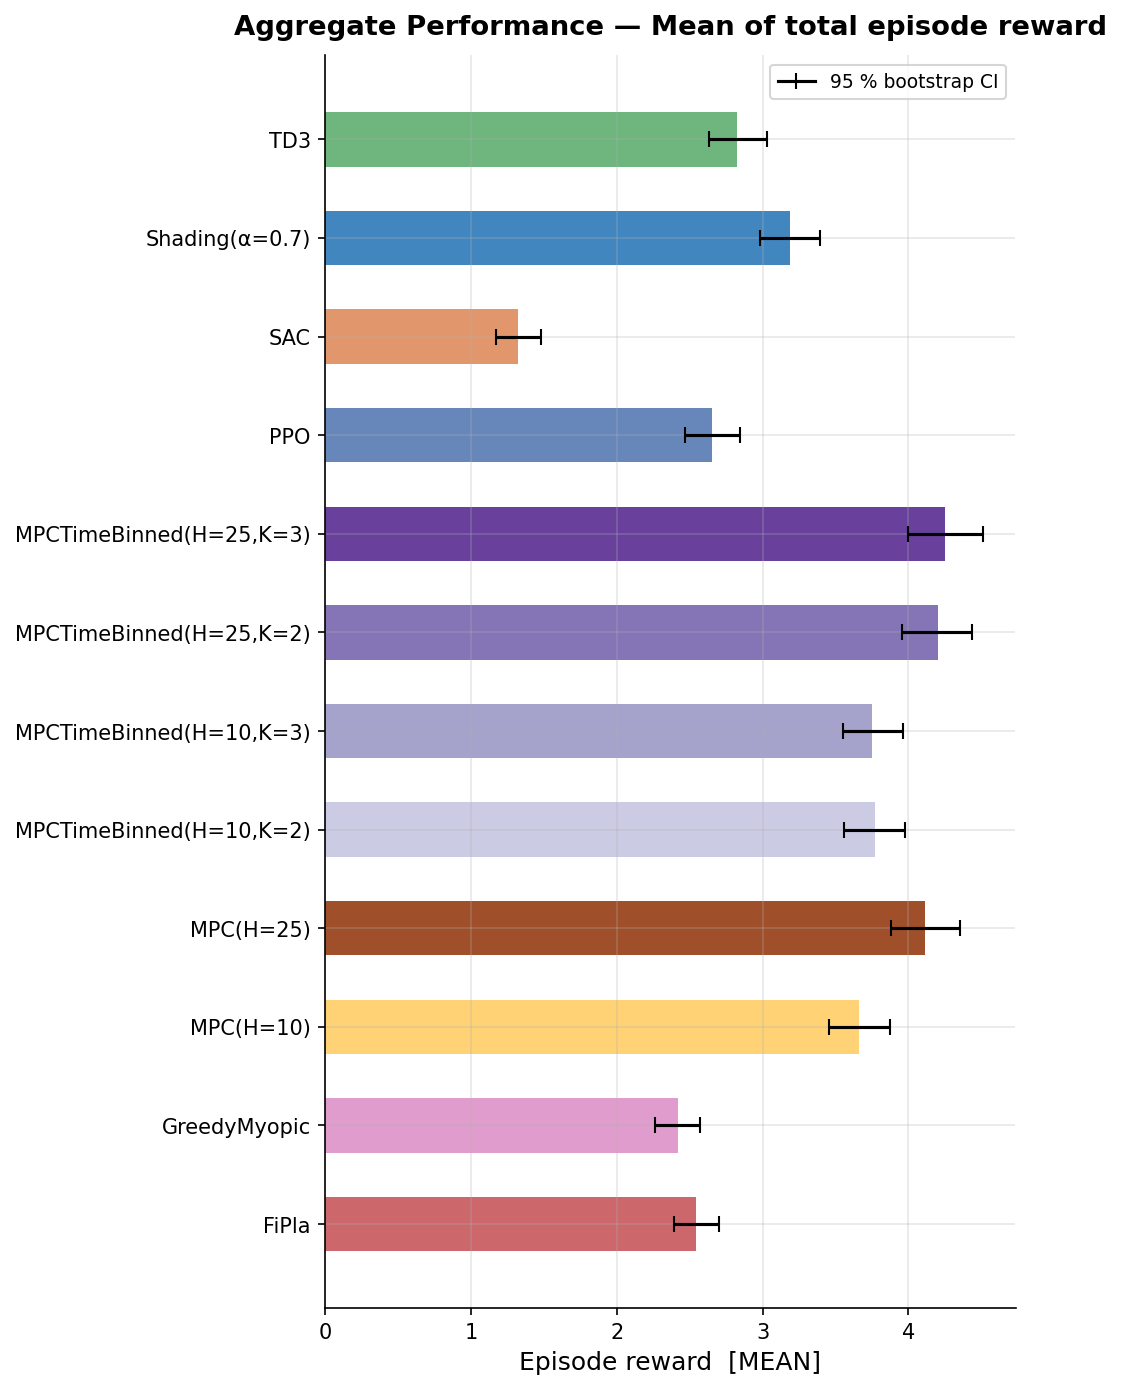

In [10]:
_ = plots.plot_aggregate_metrics(scores_eta100, metric="mean", normalize_by=None, filename="aggregate_metrics_eta100.pdf")

### Performance profiles

Fraction of seeds on which each policy achieves at least a given score threshold τ. A curve that is higher and further to the right indicates more consistent performance across seeds.

  Saved → /home/epatard/Bureau/Inria/repeated-auction-library/dynamauction/benchmark/plots/performance_profiles_eta50.pdf


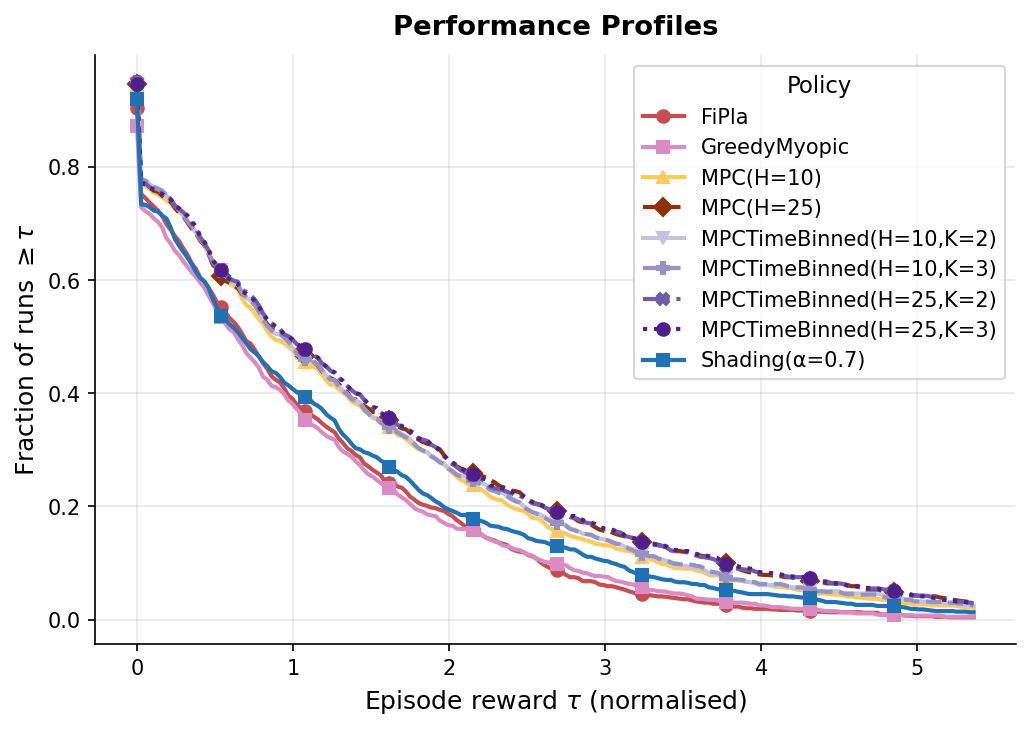

In [19]:
_ = plots.plot_performance_profiles(scores_eta50, filename="performance_profiles_eta50.pdf")

  Saved → /home/epatard/Bureau/Inria/repeated-auction-library/dynamauction/benchmark/plots/performance_profiles_eta100.pdf


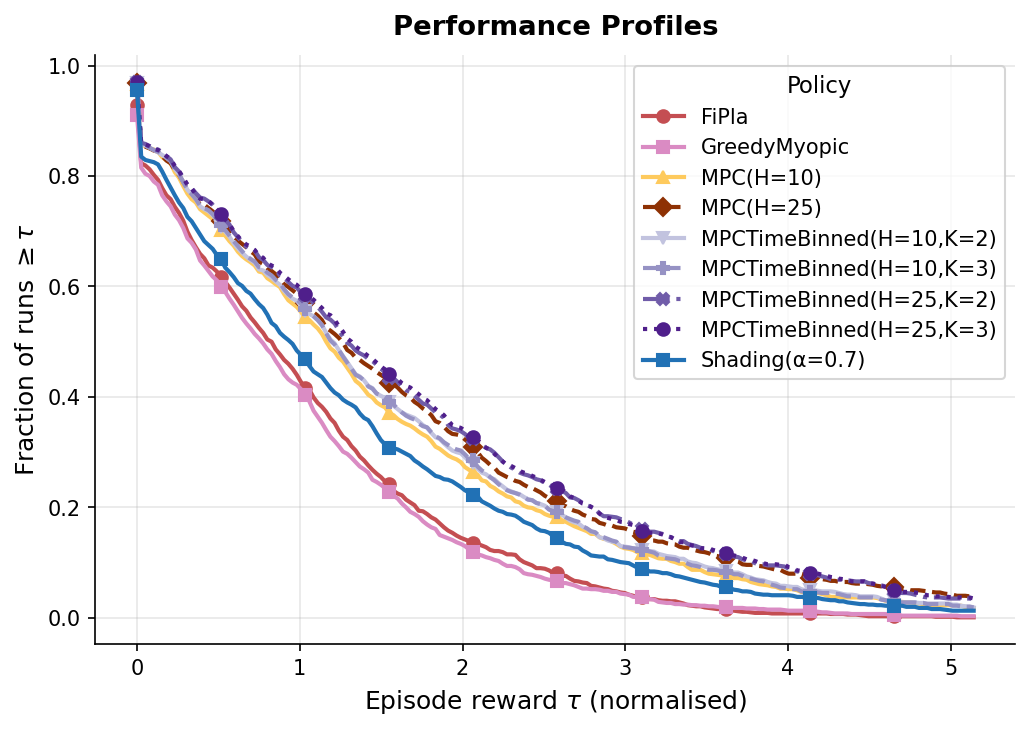

In [20]:
_ = plots.plot_performance_profiles(scores_eta100, filename="performance_profiles_eta100.pdf")

### Cumulative reward over time

Mean cumulative reward as a function of **normalised campaign time** (each episode's
time axis is rescaled to [0, 1] before averaging), across 1 000 seeds.
Shaded bands show ±1 standard deviation.

  Saved → /home/epatard/Bureau/Inria/paper_ready_code/dynamauction/benchmark/plots/cumulative_reward_eta50.pdf


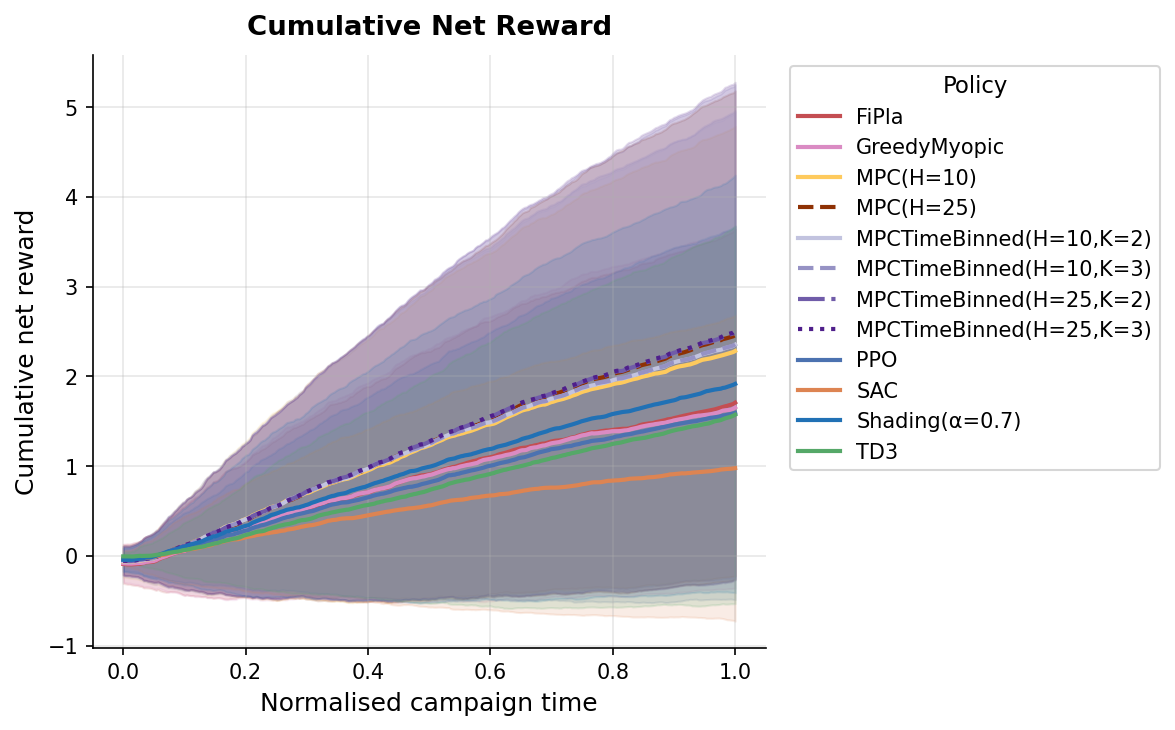

In [8]:
_ = plots.plot_cumulative_reward(df_eta50, filename="cumulative_reward_eta50.pdf")

  Saved → /home/epatard/Bureau/Inria/paper_ready_code/dynamauction/benchmark/plots/cumulative_reward_eta100.pdf


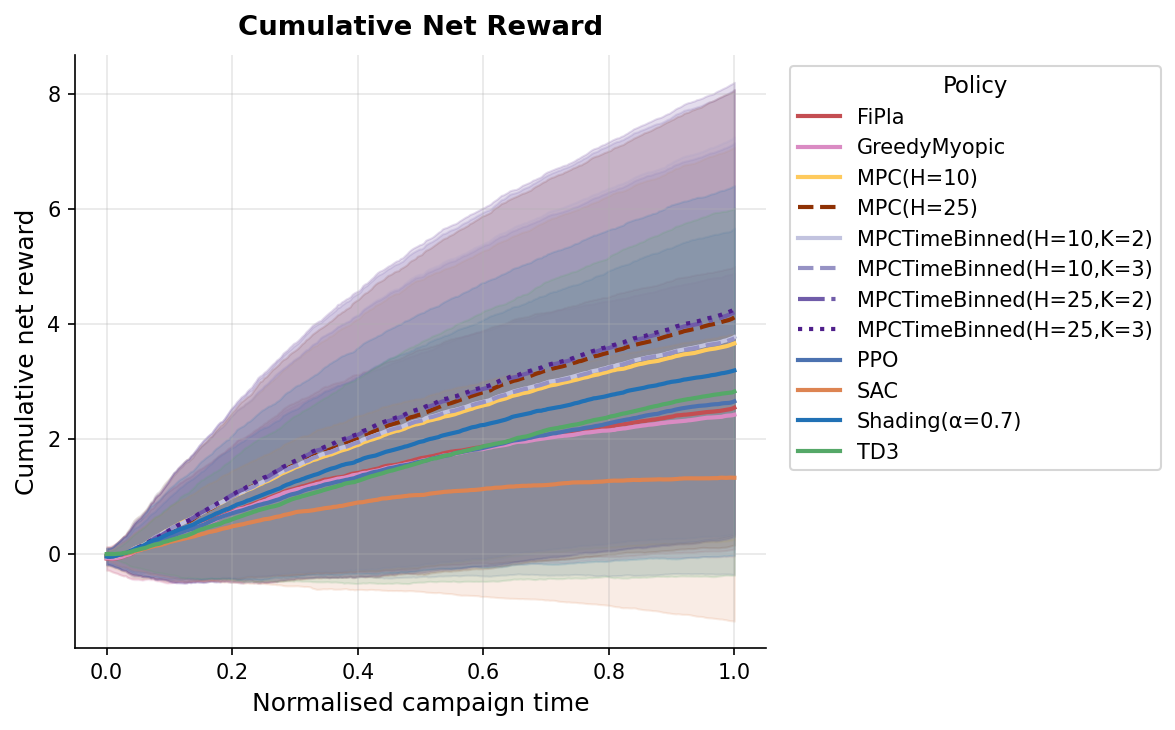

In [9]:
_ = plots.plot_cumulative_reward(df_eta100, filename="cumulative_reward_eta100.pdf")

### Episode reward distribution

Distribution of total episode reward across 1000 seeds for each policy.

/home/epatard/Bureau/Inria/repeated-auction-library/dynamauction/benchmark/plots.py:403: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=summary, x="policy", y="episode_reward",
/home/epatard/Bureau/Inria/repeated-auction-library/dynamauction/benchmark/plots.py:412: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=40, ha="right", fontsize=9)


  Saved → /home/epatard/Bureau/Inria/repeated-auction-library/dynamauction/benchmark/plots/reward_distribution_eta50.pdf


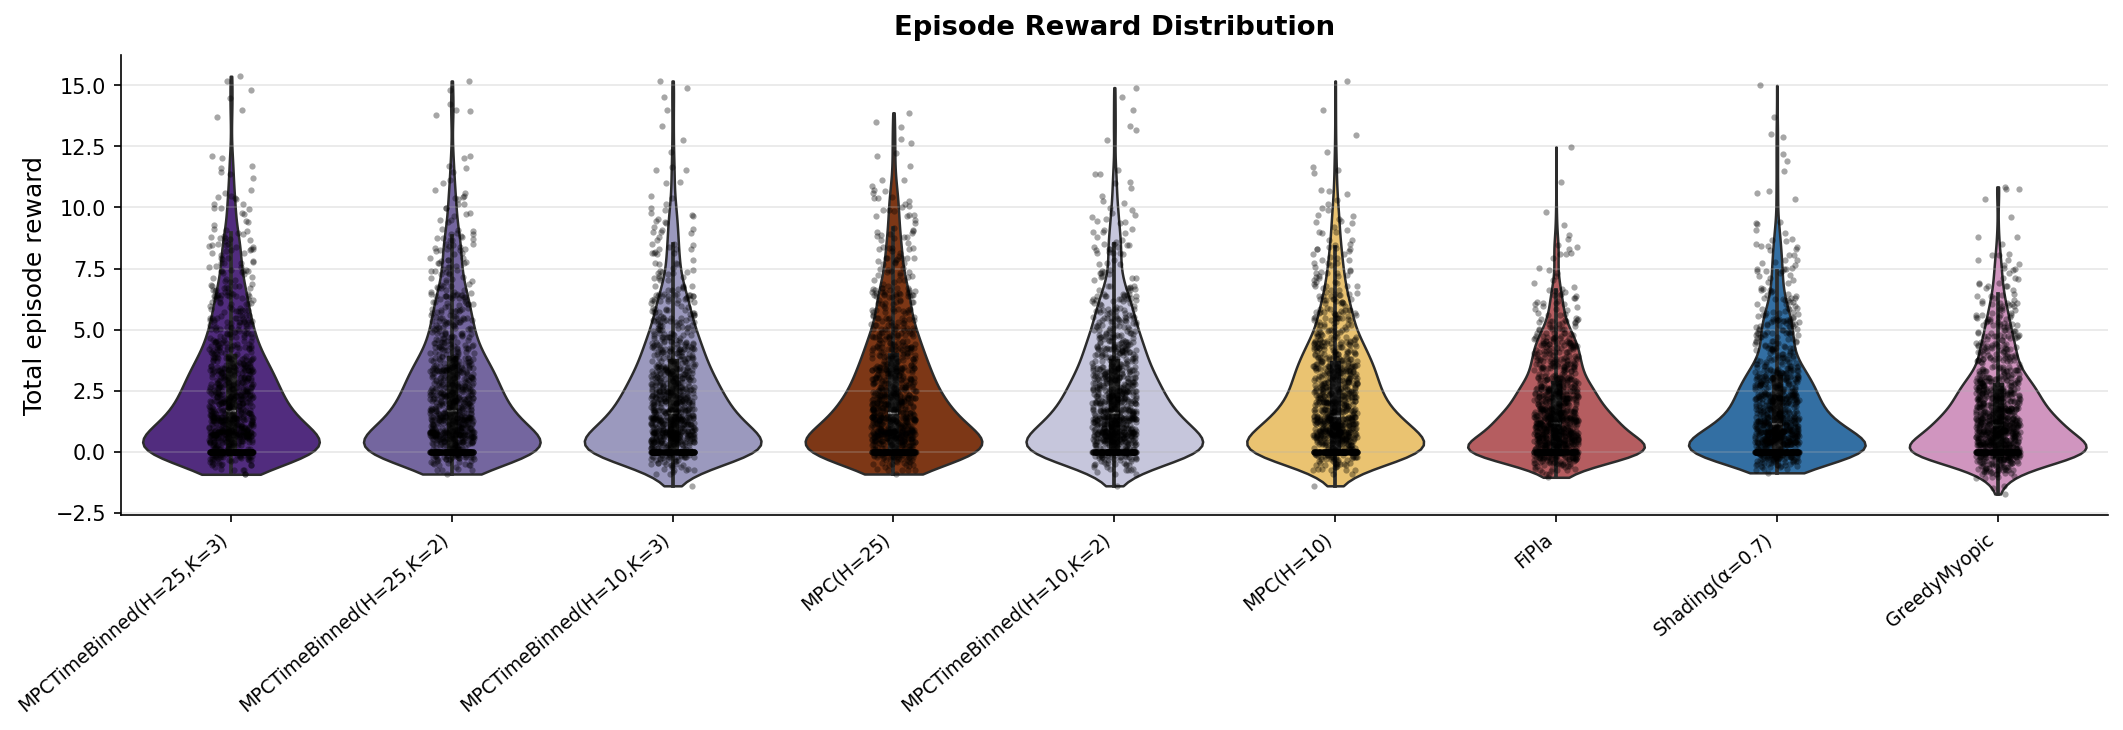

In [23]:
_ = plots.plot_reward_distribution(df_eta50, filename="reward_distribution_eta50.pdf")

/home/epatard/Bureau/Inria/repeated-auction-library/dynamauction/benchmark/plots.py:403: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=summary, x="policy", y="episode_reward",
/home/epatard/Bureau/Inria/repeated-auction-library/dynamauction/benchmark/plots.py:412: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=40, ha="right", fontsize=9)


  Saved → /home/epatard/Bureau/Inria/repeated-auction-library/dynamauction/benchmark/plots/reward_distribution_eta100.pdf


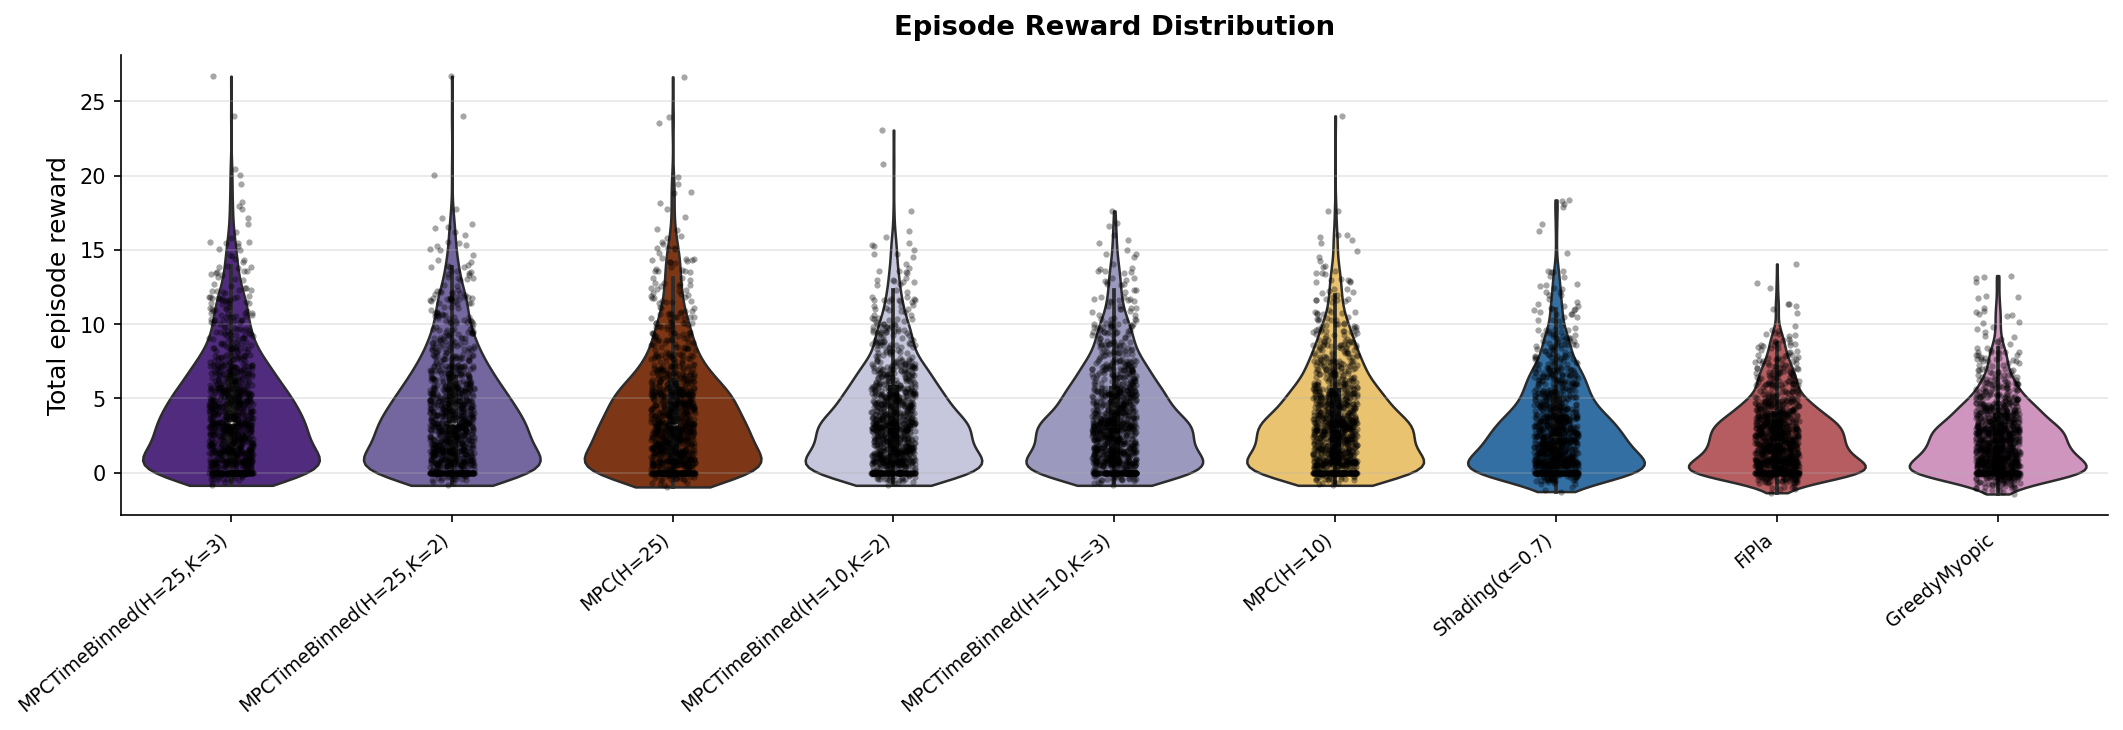

In [24]:
_ = plots.plot_reward_distribution(df_eta100, filename="reward_distribution_eta100.pdf")

### Context dynamics

Evolution of the context signal `ctx` and the expected reward over **normalised
campaign time** (rescaled to [0, 1] per seed), averaged across 1 000 seeds.
Illustrates how the survival kernel erodes the display value as the campaign progresses.

  Saved → /home/epatard/Bureau/Inria/paper_ready_code/dynamauction/benchmark/plots/context_dynamics_eta50.pdf


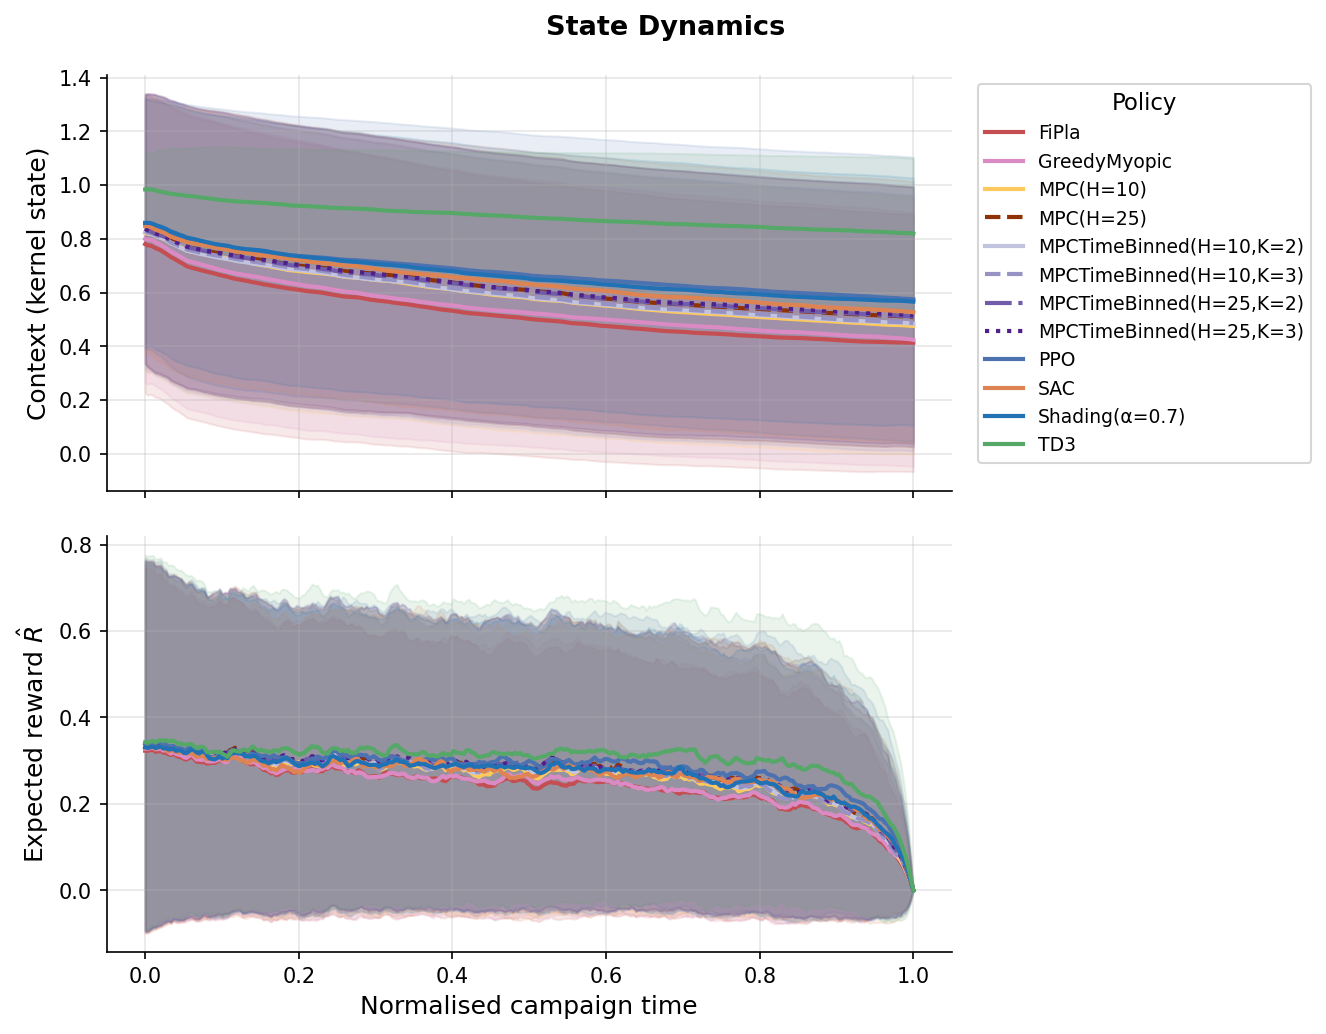

In [10]:
_ = plots.plot_context_dynamics(df_eta50, filename="context_dynamics_eta50.pdf")

  Saved → /home/epatard/Bureau/Inria/paper_ready_code/dynamauction/benchmark/plots/context_dynamics_eta100.pdf


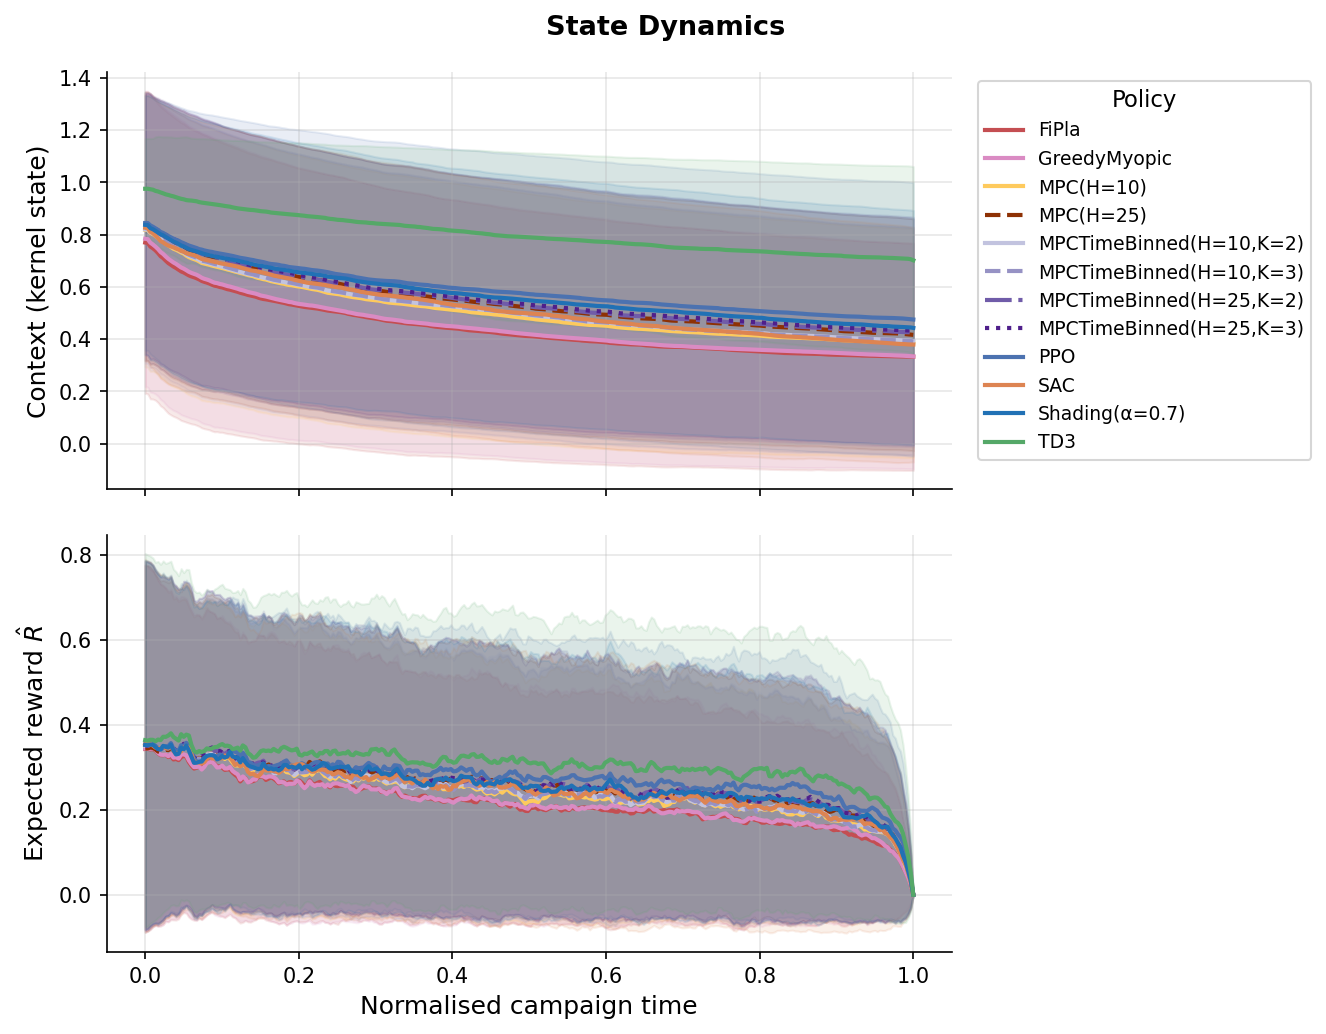

In [11]:
_ = plots.plot_context_dynamics(df_eta100, filename="context_dynamics_eta100.pdf")

### Bid distributions

Distribution of submitted bids across all steps and seeds for each policy, overlaid with the expected value signal (`expected_reward`). Shows how well each policy aligns bids with true value.

  Saved → /home/epatard/Bureau/Inria/repeated-auction-library/dynamauction/benchmark/plots/bid_distributions_eta50.pdf


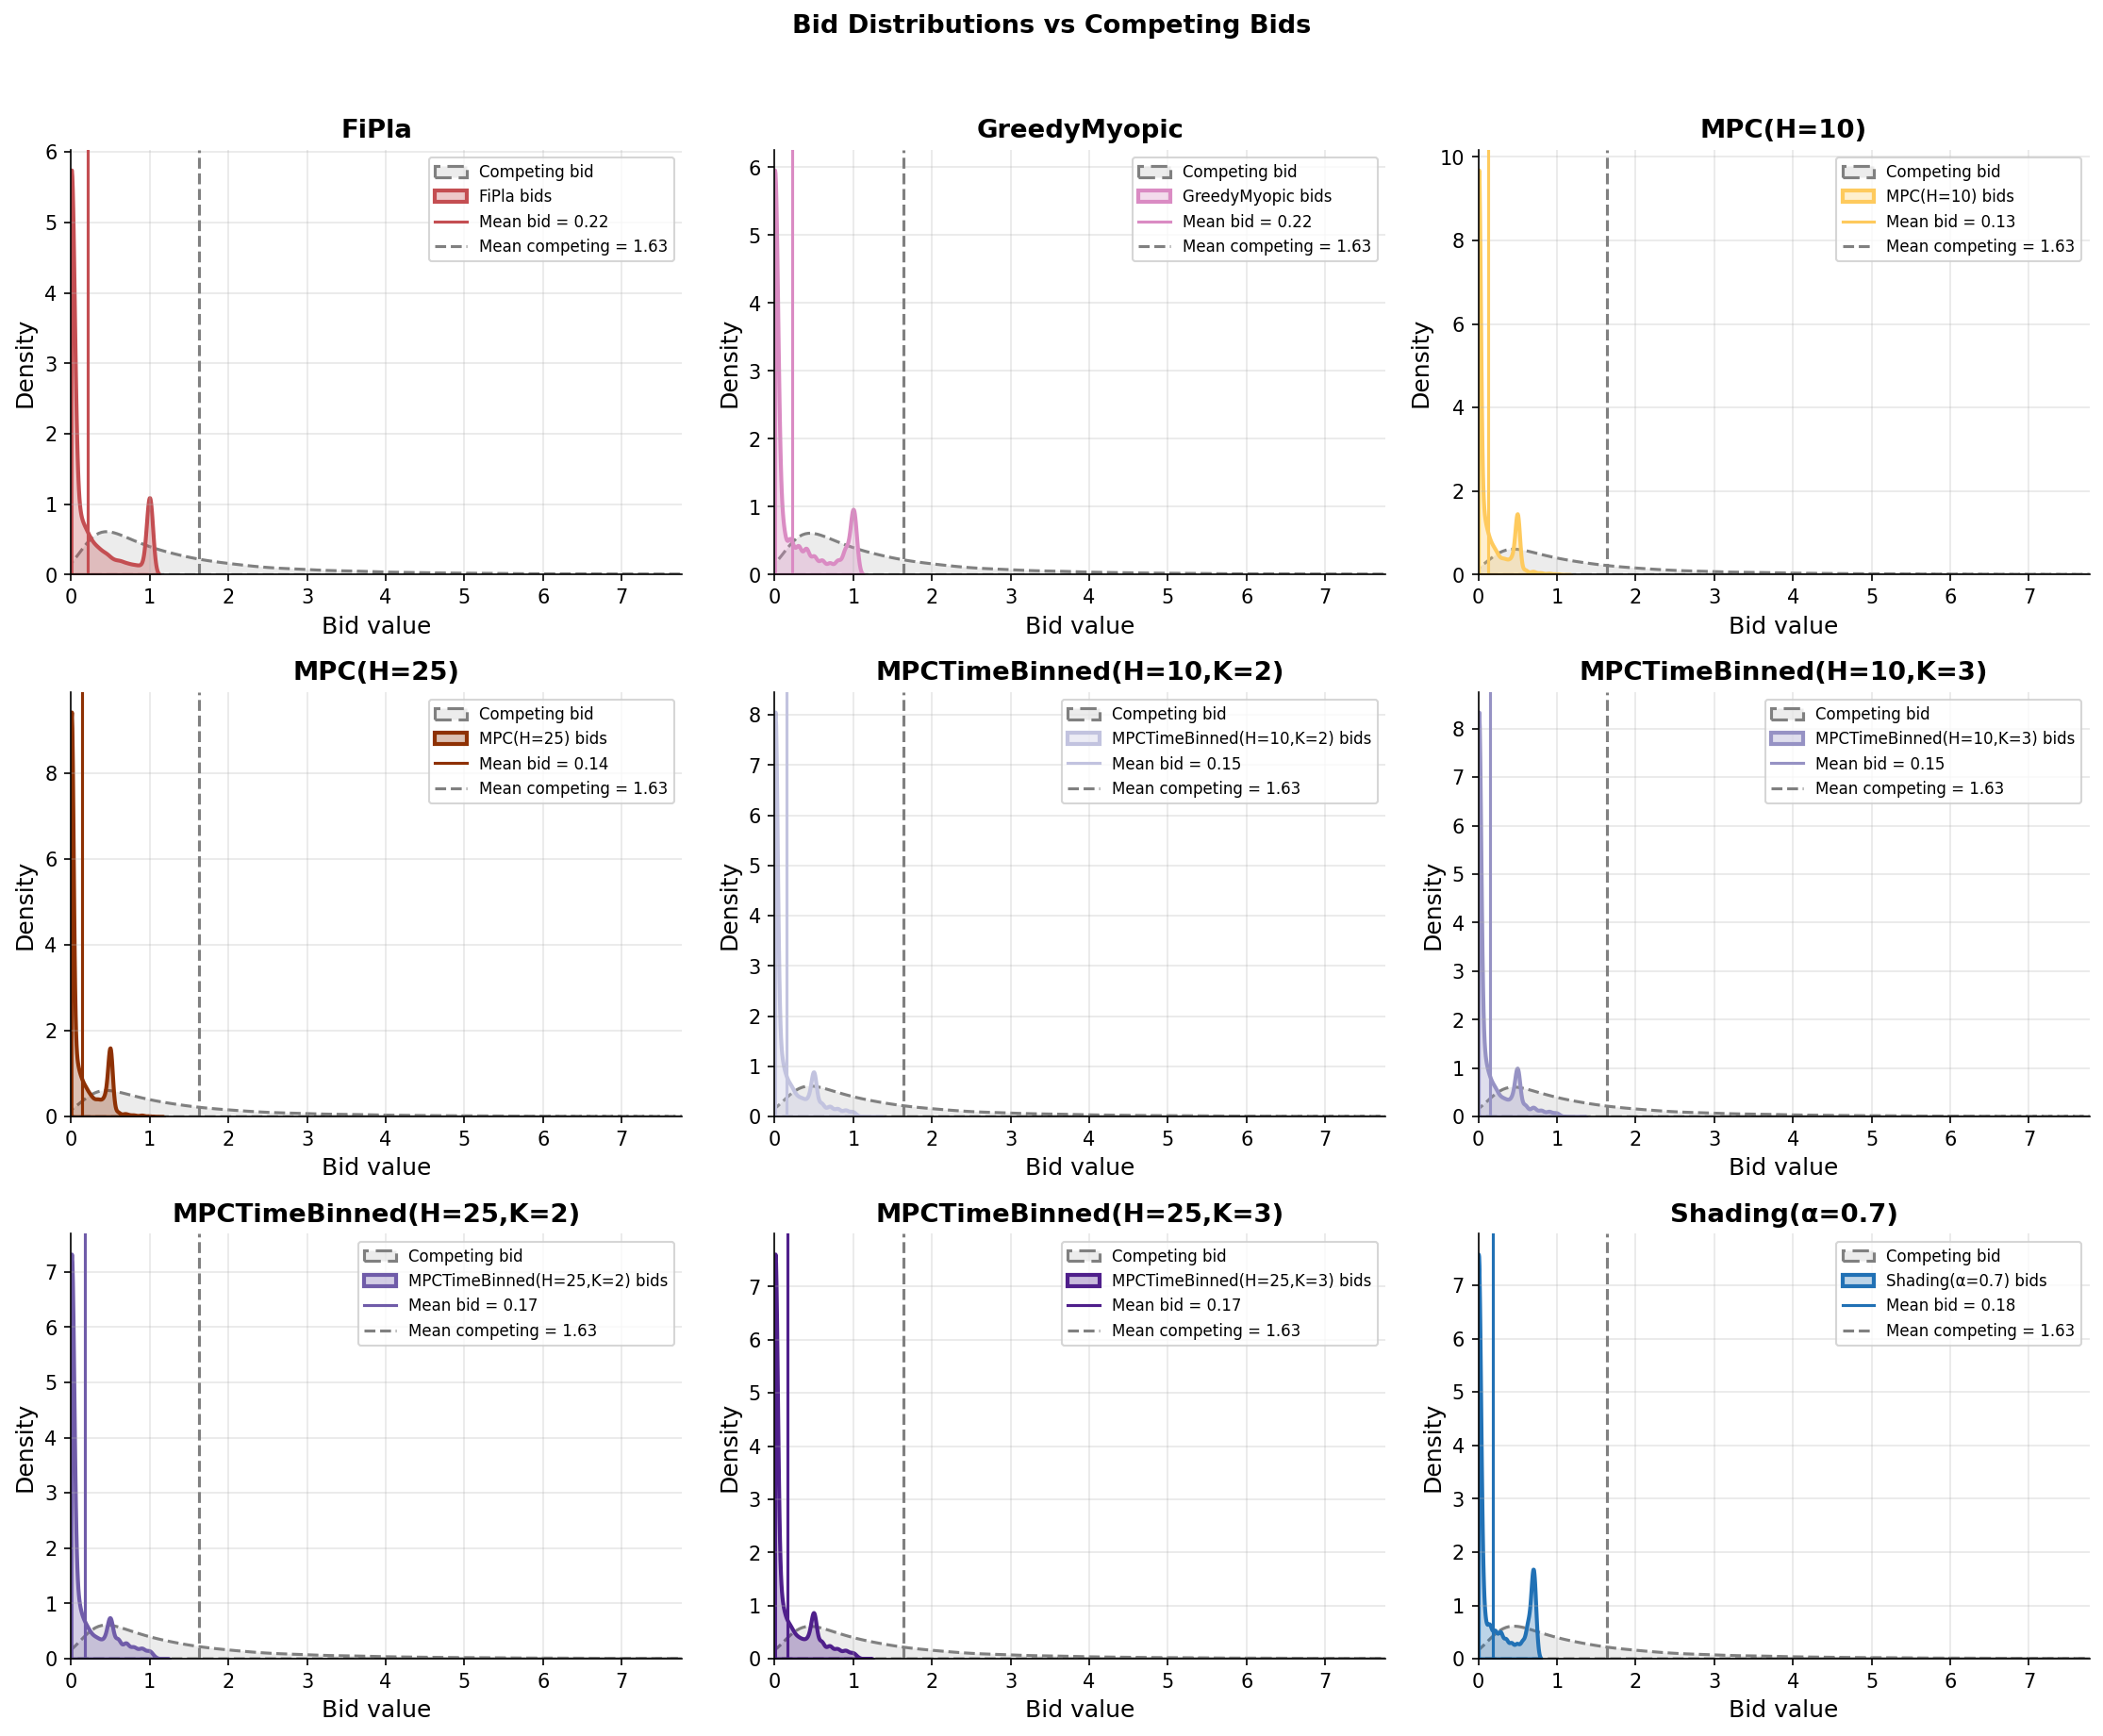

In [28]:
_ = plots.plot_bid_distributions(df_eta50, filename="bid_distributions_eta50.pdf")

  Saved → /home/epatard/Bureau/Inria/repeated-auction-library/dynamauction/benchmark/plots/bid_distributions_eta100.pdf


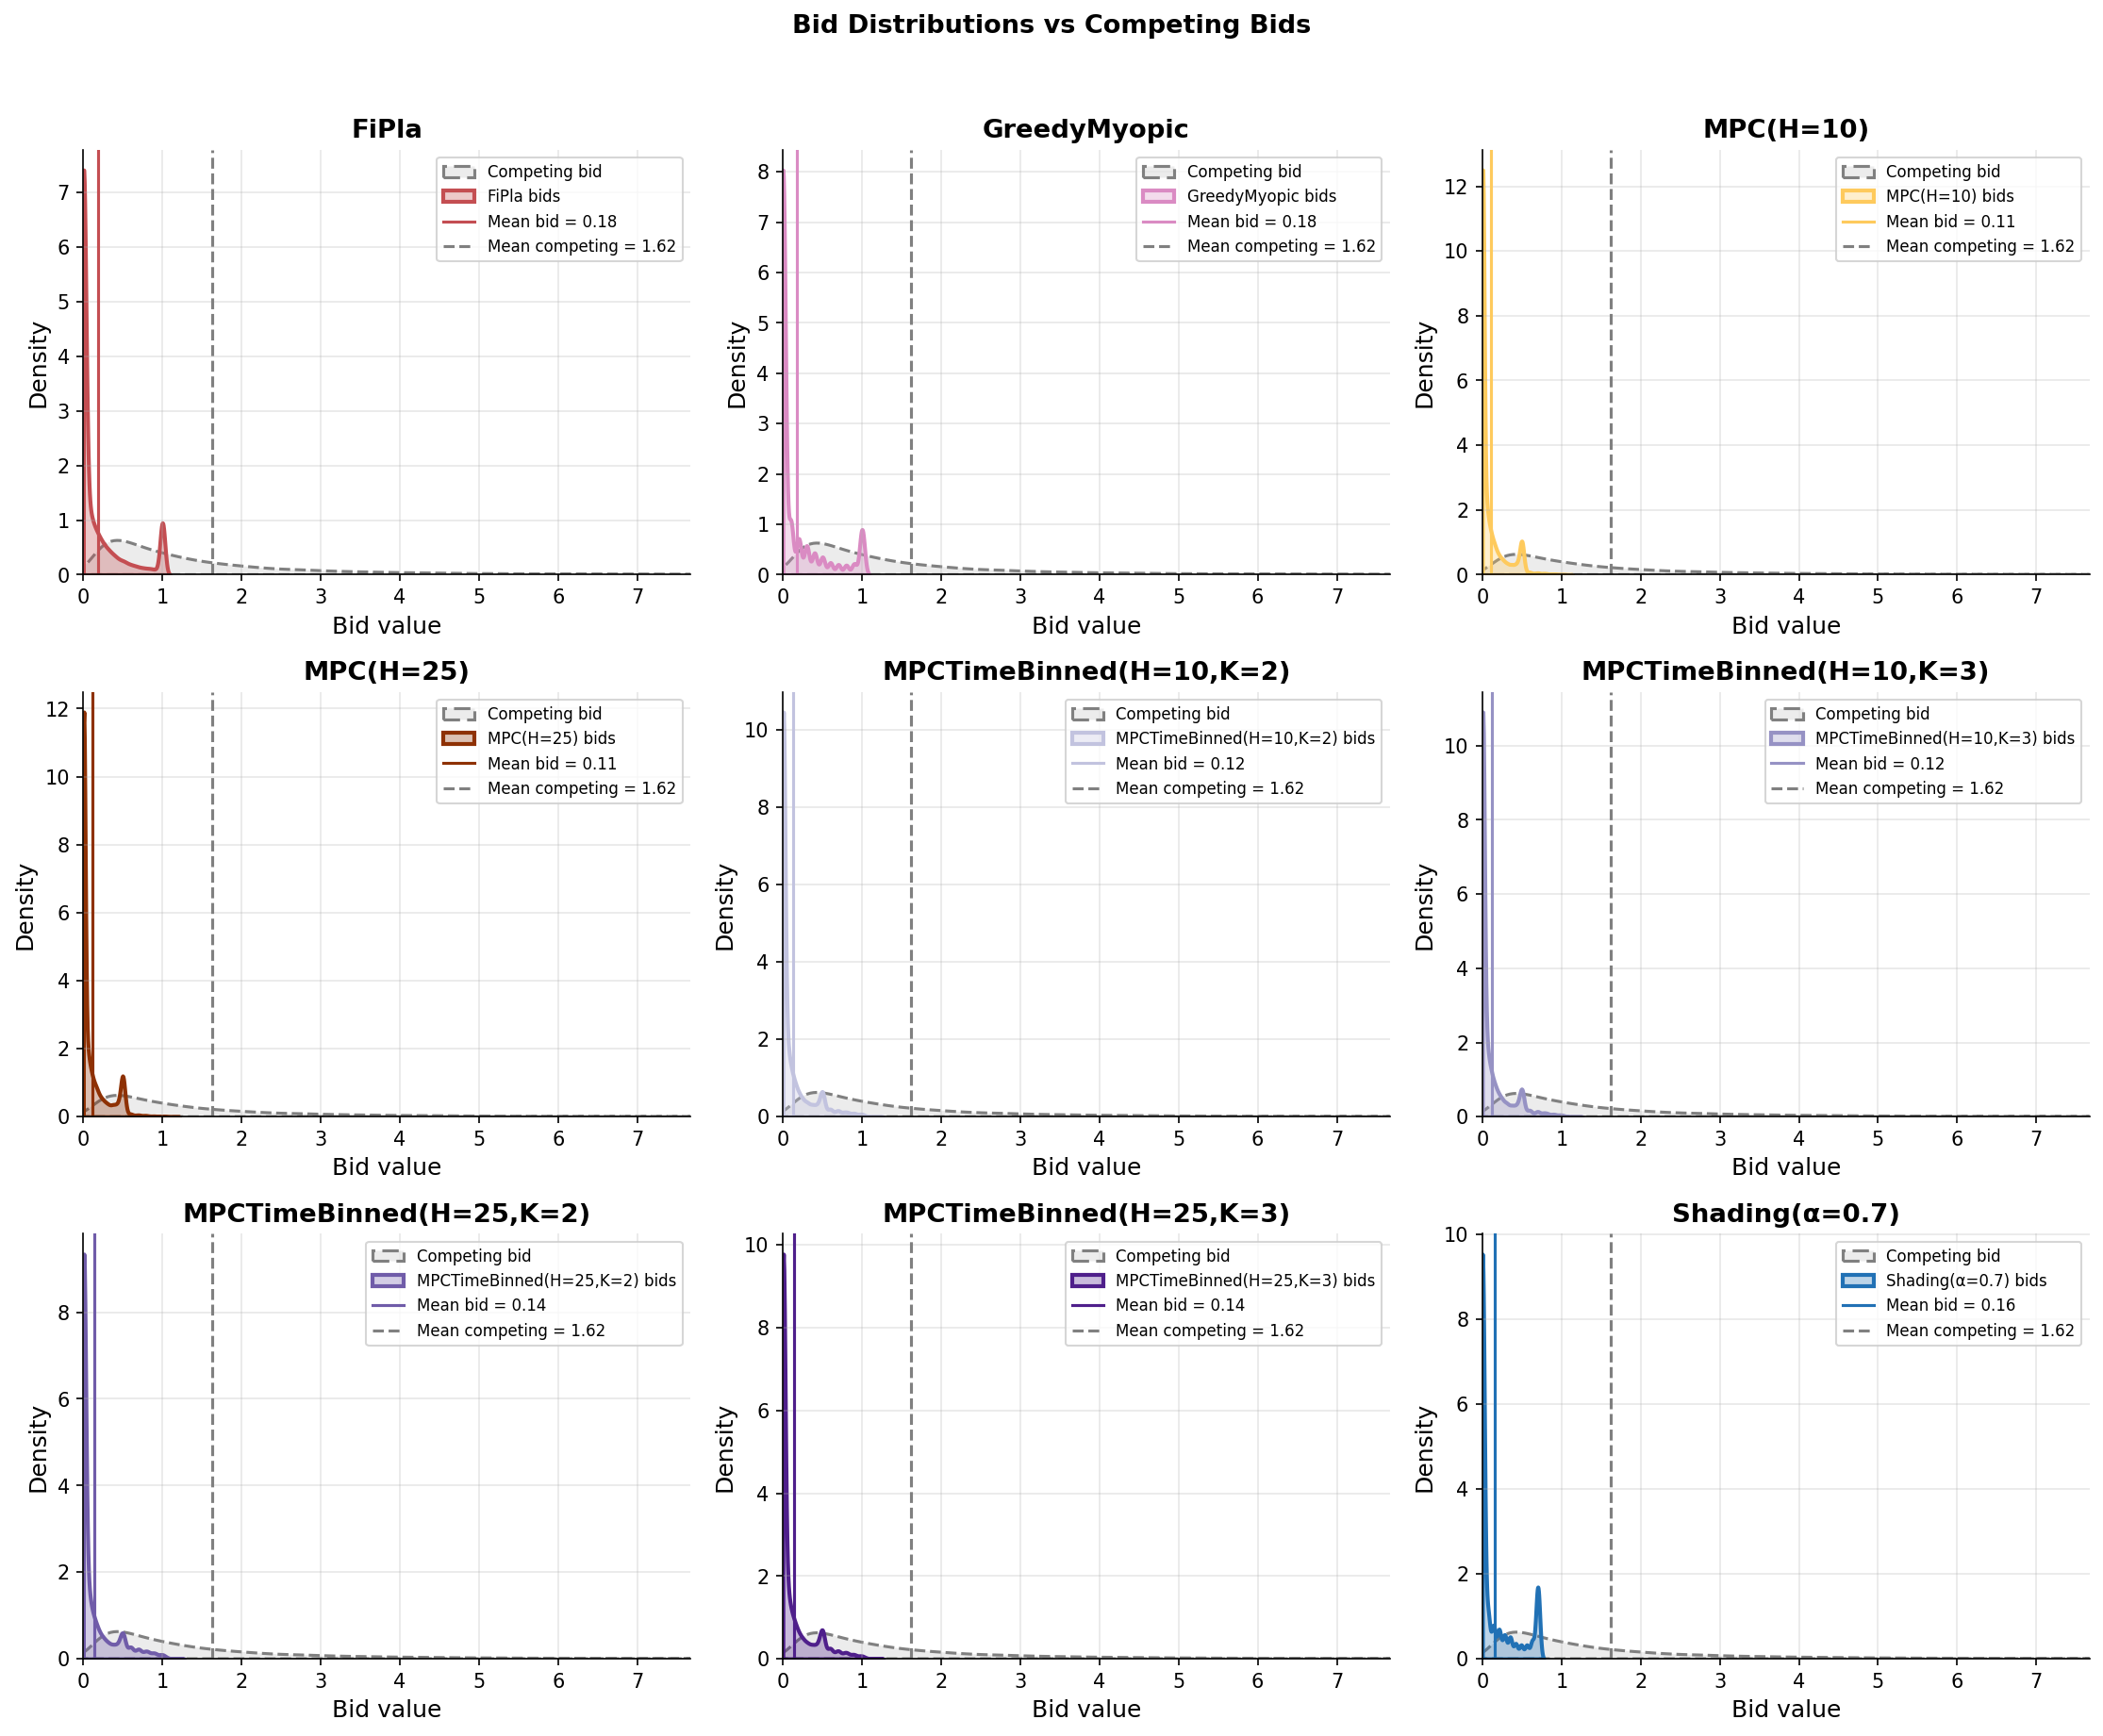

In [29]:
_ = plots.plot_bid_distributions(df_eta100, filename="bid_distributions_eta100.pdf")

### Win rate

Fraction of auctions won per policy, averaged over seeds. Under second-price rules the truthful bid (FiPla) is optimal, so its win rate serves as the upper reference.

/home/epatard/Bureau/Inria/repeated-auction-library/dynamauction/benchmark/plots.py:636: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=summary, x="policy", y="win_rate",
/home/epatard/Bureau/Inria/repeated-auction-library/dynamauction/benchmark/plots.py:643: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=40, ha="right", fontsize=9)


  Saved → /home/epatard/Bureau/Inria/repeated-auction-library/dynamauction/benchmark/plots/win_rate_eta50.pdf


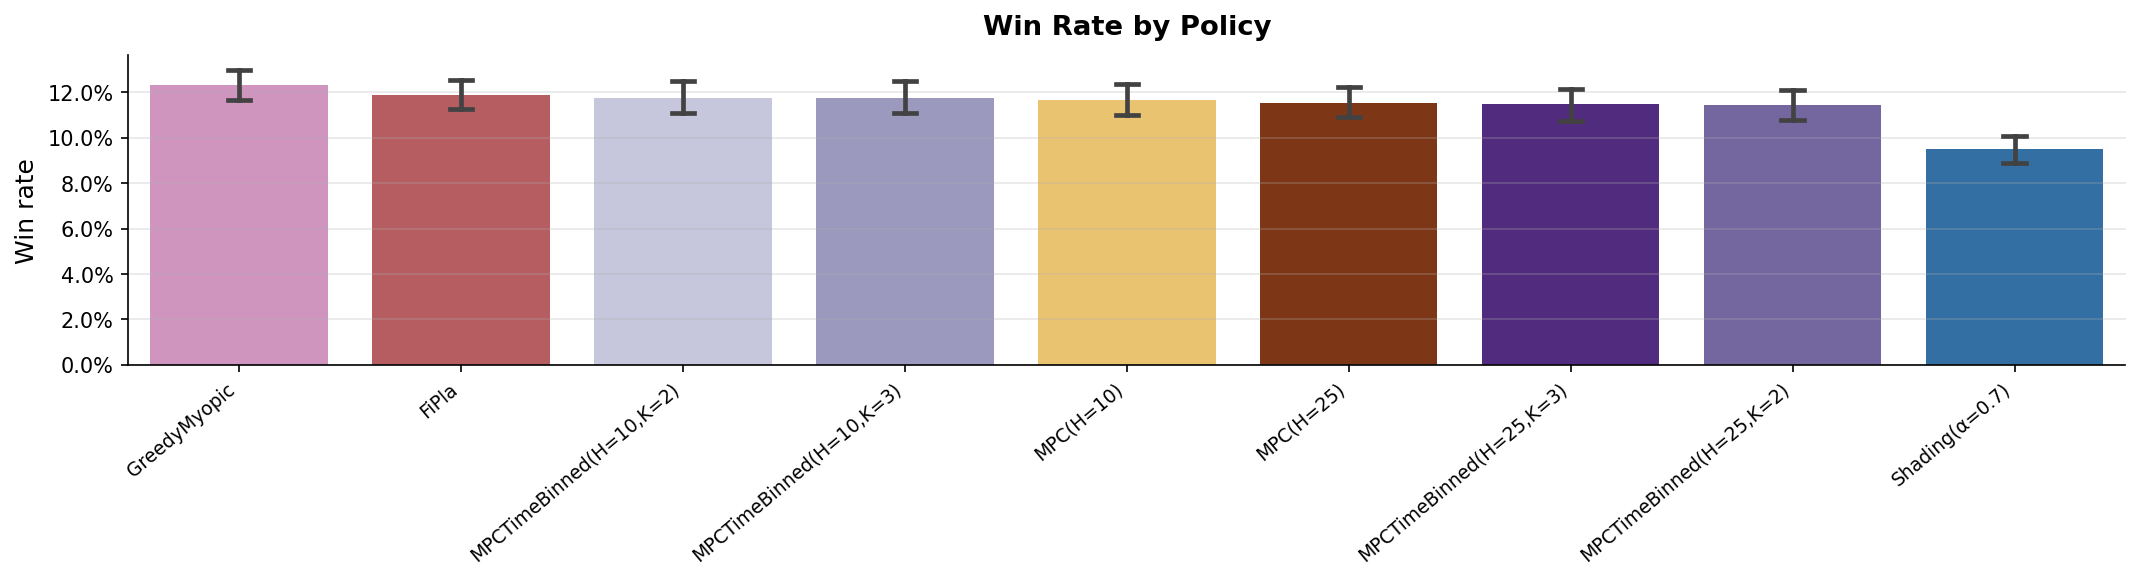

In [30]:
_ = plots.plot_win_rate(df_eta50, filename="win_rate_eta50.pdf")

/home/epatard/Bureau/Inria/repeated-auction-library/dynamauction/benchmark/plots.py:636: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=summary, x="policy", y="win_rate",
/home/epatard/Bureau/Inria/repeated-auction-library/dynamauction/benchmark/plots.py:643: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=40, ha="right", fontsize=9)


  Saved → /home/epatard/Bureau/Inria/repeated-auction-library/dynamauction/benchmark/plots/win_rate_eta100.pdf


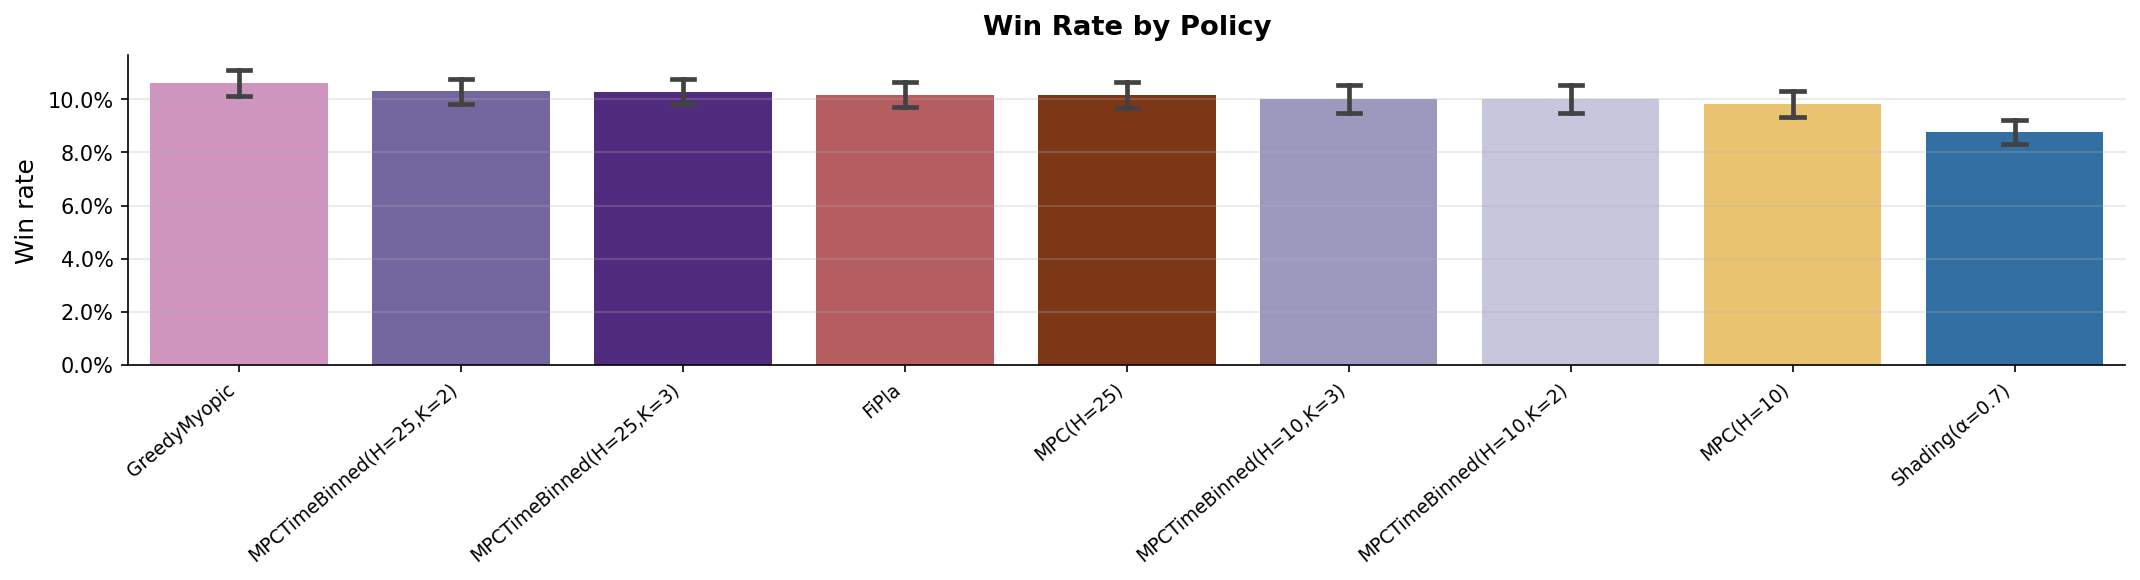

In [31]:
_ = plots.plot_win_rate(df_eta100, filename="win_rate_eta100.pdf")

### MPC's optimal alphas

At each auction step, MPC-family policies select the shading multiplier α* that maximises the estimated planning return over a rolling horizon. The distribution below shows which α* values are preferred across all steps and seeds, a concentration near high α values indicates the policy tends to bid aggressively, while a spread across the candidate set suggests the optimal multiplier is context-dependent.

/home/epatard/Bureau/Inria/repeated-auction-library/dynamauction/benchmark/plots.py:806: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=mpc_df, x="policy", y="alpha_chosen",
/home/epatard/Bureau/Inria/repeated-auction-library/dynamauction/benchmark/plots.py:820: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=40, ha="right", fontsize=9)


  Saved → /home/epatard/Bureau/Inria/repeated-auction-library/dynamauction/benchmark/plots/mpc_alpha_chosen_eta50.pdf


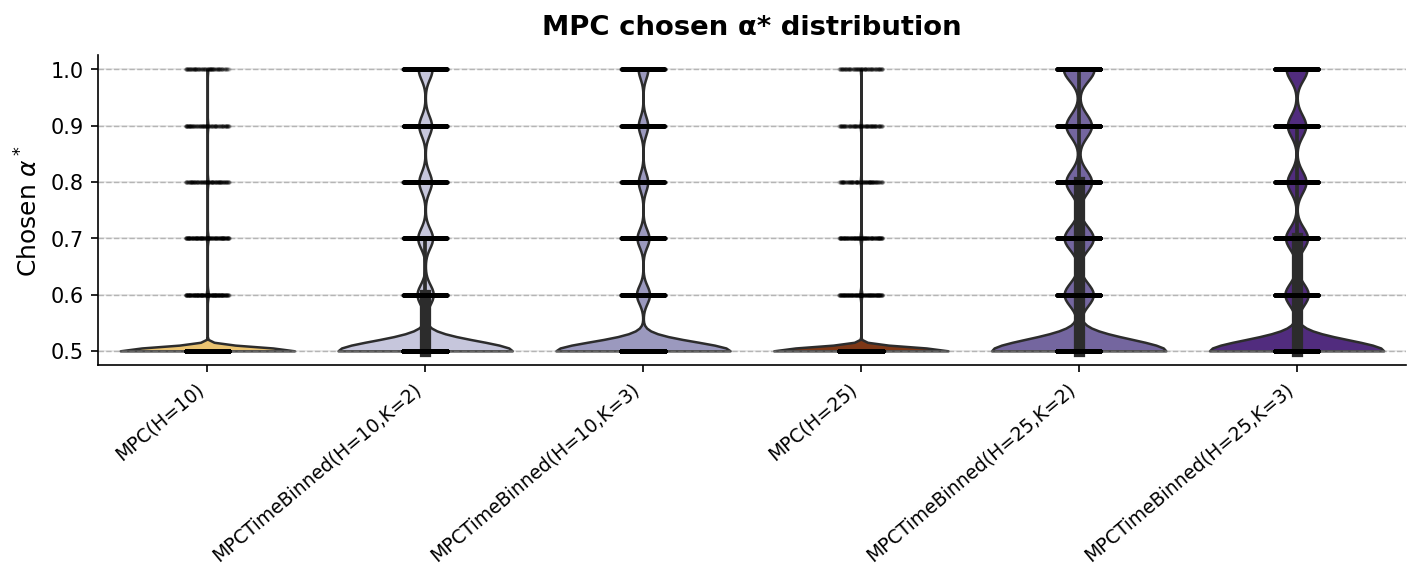

In [32]:
_ = plots.plot_mpc_alpha_chosen(df_eta50, filename="mpc_alpha_chosen_eta50.pdf")

/home/epatard/Bureau/Inria/repeated-auction-library/dynamauction/benchmark/plots.py:806: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=mpc_df, x="policy", y="alpha_chosen",
/home/epatard/Bureau/Inria/repeated-auction-library/dynamauction/benchmark/plots.py:820: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=40, ha="right", fontsize=9)


  Saved → /home/epatard/Bureau/Inria/repeated-auction-library/dynamauction/benchmark/plots/mpc_alpha_chosen_eta100.pdf


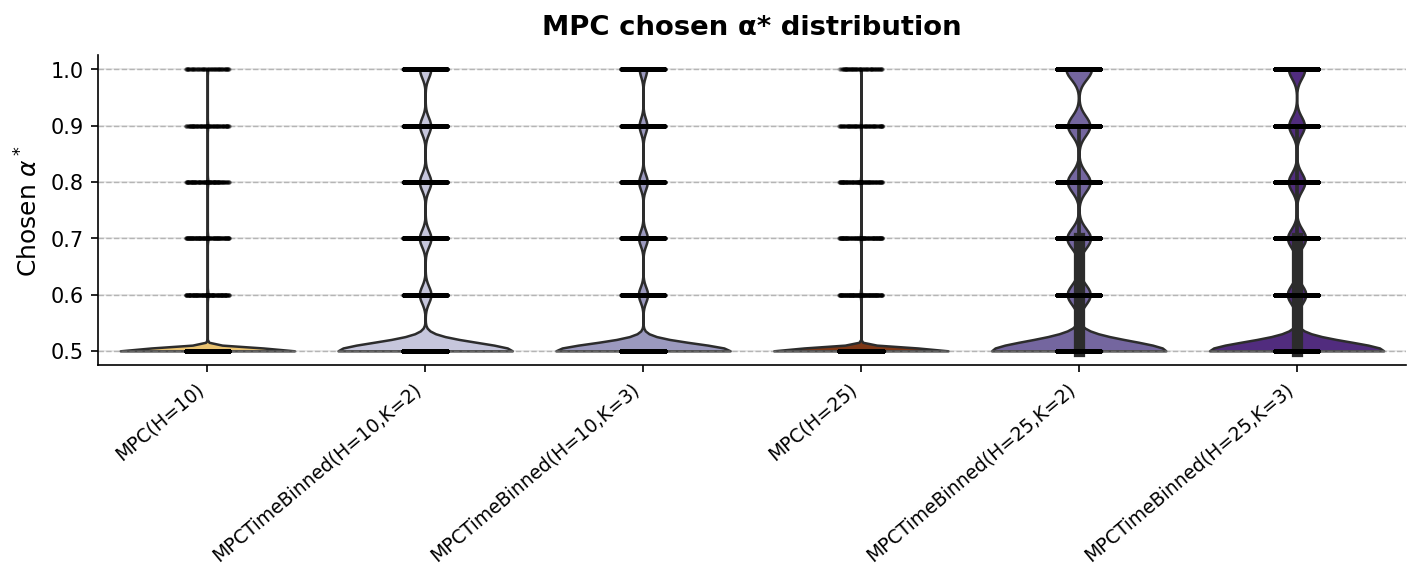

In [33]:
_ = plots.plot_mpc_alpha_chosen(df_eta100, filename="mpc_alpha_chosen_eta100.pdf")

### MPC chosen α* over normalised campaign time

Because campaign horizons are exponentially distributed (different length per seed), time is normalised to [0, 1] for each run before averaging. The curves show how the preferred shading multiplier evolves from the start to the end of a campaign.

  Saved → /home/epatard/Bureau/Inria/repeated-auction-library/dynamauction/benchmark/plots/mpc_alpha_over_time_eta50.pdf


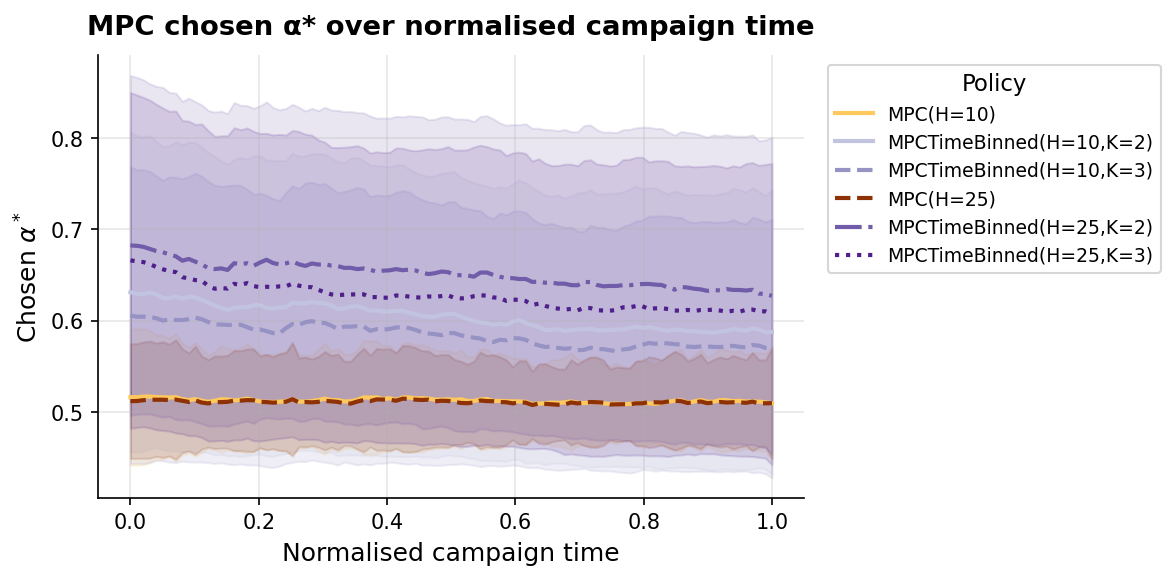

In [10]:
_ = plots.plot_alpha_over_normalized_time(df_eta50, filename="mpc_alpha_over_time_eta50.pdf")

  Saved → /home/epatard/Bureau/Inria/repeated-auction-library/dynamauction/benchmark/plots/mpc_alpha_over_time_eta100.pdf


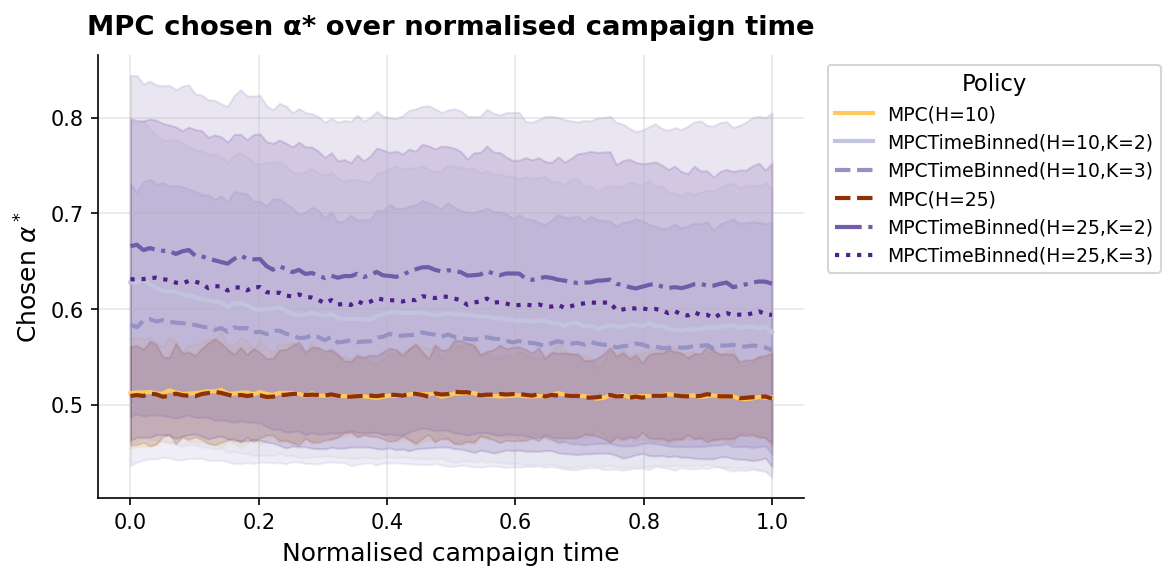

In [11]:
_ = plots.plot_alpha_over_normalized_time(df_eta100, filename="mpc_alpha_over_time_eta100.pdf")